# 03 — Raw Native YOLO26n Training

Full fine-tune from the pinned COCO YOLO26n on this run's S20 export with the native Ultralytics trainer. best.pt is selected on this policy's calibration split; development stays untouched until 04.

**Inputs:** v0.yaml (this folder) training args; runs/v0-YYYY-MM-DD/data; weights/yolo26n.pt.

**Outputs:** runs/v0-YYYY-MM-DD/train/{args.yaml,results.csv,weights/,complete.json} only after ALLOW_TRAINING=True.

**Prerequisites:** Run 02 separately. No upstream notebook is executed.

**Outline**

- [1. Configuration](#section-1)
- [2. Native Training](#section-2)
- [3. Training Summary](#section-3)

<a id="section-1"></a>

## 1. Configuration

RUN_DATE=None uses the newest prepared run. Native resume is explicit.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from vehicle_detection.common import project_root, require_paths
from vehicle_detection.experiment_data import load_experiment
from vehicle_detection.training import train_experiment

ROOT = project_root()
os.chdir(ROOT)  # Run All behaves the same from any kernel working directory.
EXPERIMENT = "v0"
require_paths(
    config=ROOT / f"notebooks/experiments/{EXPERIMENT}/{EXPERIMENT}.yaml",
    shared=ROOT / "configs/data.yaml",
)
config = load_experiment(ROOT, EXPERIMENT)

RUN_DATE = None
ALLOW_TRAINING = True
RESUME = False
display(pd.Series(config["training"], name="training"))

epochs                 50
patience                0
imgsz                 640
batch                  32
workers                 8
device                  0
cache               False
amp                  True
deterministic        True
freeze                  0
pretrained           True
cls_remap            True
optimizer             SGD
lr0                  0.01
lrf                  0.01
momentum            0.937
weight_decay       0.0005
warmup_epochs         3.0
warmup_momentum       0.8
warmup_bias_lr        0.1
cos_lr              False
nbs                    64
rect                False
multi_scale           0.0
mosaic                1.0
close_mosaic           10
fliplr                0.5
flipud                0.0
scale                 0.5
translate             0.1
degrees               0.0
shear                 0.0
perspective           0.0
mixup                 0.0
cutmix                0.0
copy_paste            0.0
hsv_h                 0.0
hsv_s                 0.0
hsv_v       

<a id="section-2"></a>

## 2. Native Training

Every training argument comes from the version YAML; changing it after a run starts requires a new run date.

New https://pypi.org/project/ultralytics/8.4.208 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.198 🚀 Python-3.11.14 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16284MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/truong51972/projects/vehicle-detection/runs/v0-2026-11-09/data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=0, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, 

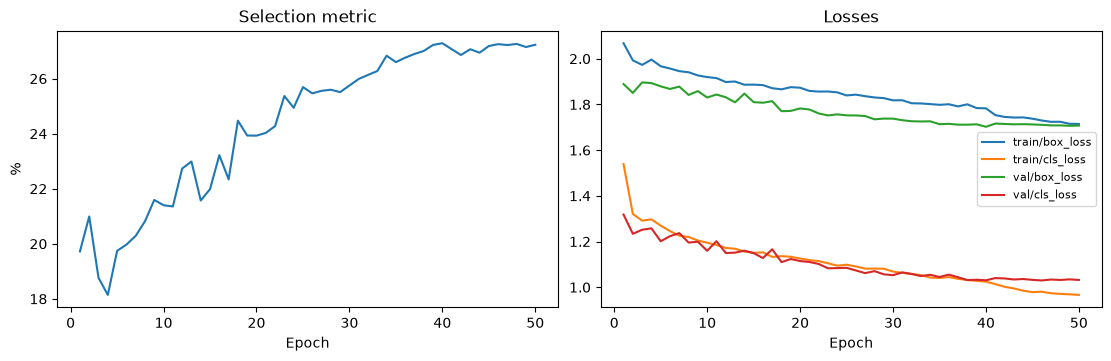

In [2]:
try:
    history = train_experiment(
        ROOT, EXPERIMENT, RUN_DATE, allow_training=ALLOW_TRAINING, resume=RESUME
    )
except FileNotFoundError as error:
    history = pd.DataFrame()
    print(error)
if not history.empty:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
    axes[0].plot(history.epoch, history["metrics/mAP50-95(B)"] * 100, label="calibration mAP50-95")
    axes[0].set(xlabel="Epoch", ylabel="%", title="Selection metric")
    for column in ("train/box_loss", "train/cls_loss", "val/box_loss", "val/cls_loss"):
        axes[1].plot(history.epoch, history[column], label=column)
    axes[1].set(xlabel="Epoch", title="Losses")
    axes[1].legend(fontsize=8)
    plt.show()

<a id="section-3"></a>

## 3. Training Summary

Single seed; the calibration curve is a selection signal, not the reported result.

In [3]:
if not history.empty:
    best = history.loc[history["metrics/mAP50-95(B)"].idxmax()]
    score = best["metrics/mAP50-95(B)"]
    print(f"Epochs: {len(history)} | best calibration mAP50-95 {score:.4f} @ {int(best.epoch)}")
print("Final holdout stays sealed.")

Epochs: 50 | best calibration mAP50-95 0.2728 @ 40
Final holdout stays sealed.
